In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df = pd.read_csv("simulations_laplace_poisson")

In [6]:
df_plot = df.copy()

df_plot["method"] = np.where(
    df_plot["skewed"],
    "Skewed " + df_plot["family"],
    df_plot["family"]
)

# nicer labels
df_plot["method"] = df_plot["method"].replace({
    "gaussian": "Gaussian",
    "student_t": "Student-t",
    "Skewed gaussian": "Skewed Gaussian",
    "Skewed student_t": "Skewed Student-t"
})

df_plot

,n,replicate,family,skewed,kl,method
0,2,0,gaussian,False,0.020374,Gaussian
1,2,0,gaussian,True,0.010099,Skewed Gaussian
2,2,0,student_t,False,0.032575,Student-t
3,2,0,student_t,True,0.022299,Skewed Student-t
4,4,0,gaussian,False,0.009724,Gaussian
...,...,...,...,...,...,...
11995,32,499,student_t,True,0.038567,Skewed Student-t
11996,64,499,gaussian,False,0.002510,Gaussian
11997,64,499,gaussian,True,0.000074,Skewed Gaussian
11998,64,499,student_t,False,0.042965,Student-t


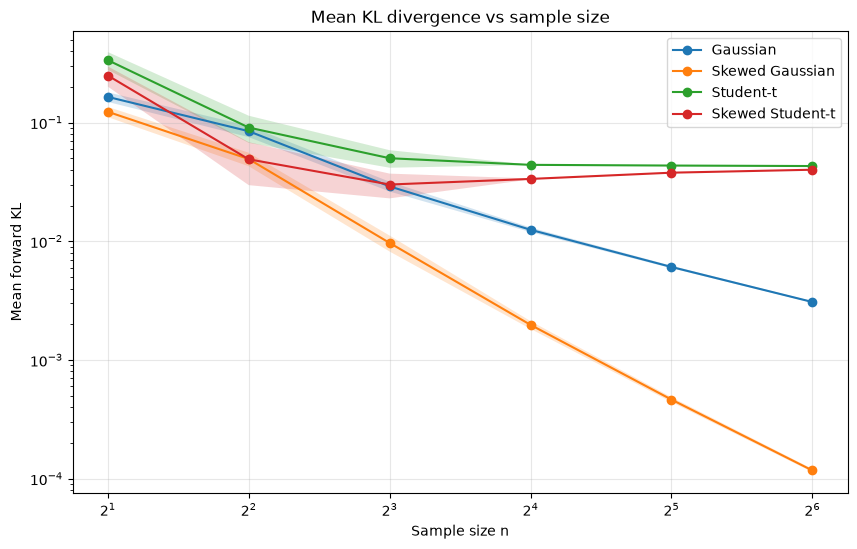

In [9]:
df_finite = df_plot[np.isfinite(df_plot["kl"])].copy()

summary = (
    df_finite
    .groupby(["n", "method"])["kl"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

summary["se"] = summary["std"] / np.sqrt(summary["count"])
summary["lower"] = summary["mean"] - 1.96 * summary["se"]
summary["upper"] = summary["mean"] + 1.96 * summary["se"]

methods = ["Gaussian", "Skewed Gaussian", "Student-t", "Skewed Student-t"]

plt.figure(figsize=(10, 6))

for method in methods:
    sub = summary[summary["method"] == method]
    plt.plot(sub["n"], sub["mean"], marker="o", label=method)
    plt.fill_between(sub["n"], sub["lower"], sub["upper"], alpha=0.2)

plt.xlabel("Sample size n")
plt.ylabel("Mean forward KL")
plt.title("Mean KL divergence vs sample size")
plt.legend()
plt.grid(alpha=0.3)
plt.yscale("log")
plt.xscale("log", base=2)
plt.show()

In [10]:
wide = (
    df_plot
    .pivot_table(
        index=["n", "replicate", "family"],
        columns="skewed",
        values="kl"
    )
    .reset_index()
)

wide = wide.rename(columns={False: "kl_plain", True: "kl_skewed"})
wide["improvement"] = wide["kl_plain"] - wide["kl_skewed"]
wide["relative_improvement"] = wide["improvement"] / wide["kl_plain"]
wide

skewed,n,replicate,family,kl_plain,kl_skewed,improvement,relative_improvement
0,2,0,gaussian,0.020374,0.010099,0.010276,0.504337
1,2,0,student_t,0.032575,0.022299,0.010276,0.315445
2,2,1,gaussian,0.087067,0.059328,0.027739,0.318591
3,2,1,student_t,0.031839,0.004100,0.027739,0.871224
4,2,2,gaussian,0.380054,0.295491,0.084563,0.222503
...,...,...,...,...,...,...,...
5995,64,497,student_t,0.042966,0.040460,0.002506,0.058324
5996,64,498,gaussian,0.003354,0.000138,0.003217,0.958971
5997,64,498,student_t,0.043035,0.039819,0.003217,0.074742
5998,64,499,gaussian,0.002510,0.000074,0.002436,0.970448


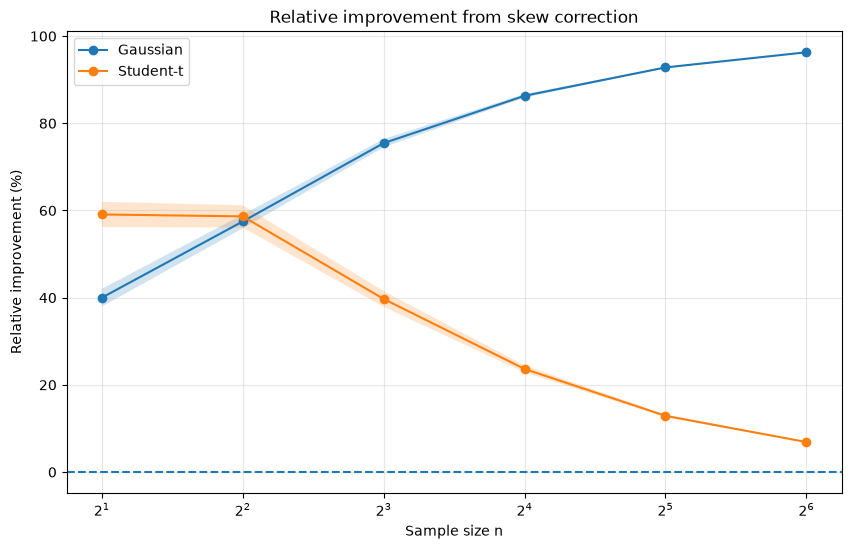

In [11]:
summary_rel = (
    wide[np.isfinite(wide["relative_improvement"])]
    .groupby(["n", "family"])["relative_improvement"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

summary_rel["se"] = summary_rel["std"] / np.sqrt(summary_rel["count"])
summary_rel["lower"] = summary_rel["mean"] - 1.96 * summary_rel["se"]
summary_rel["upper"] = summary_rel["mean"] + 1.96 * summary_rel["se"]

plt.figure(figsize=(10, 6))

for fam, label in [("gaussian", "Gaussian"), ("student_t", "Student-t")]:
    sub = summary_rel[summary_rel["family"] == fam]
    plt.plot(sub["n"], 100 * sub["mean"], marker="o", label=label)
    plt.fill_between(sub["n"], 100 * sub["lower"], 100 * sub["upper"], alpha=0.2)

plt.axhline(0, linestyle="--")
plt.xlabel("Sample size n")
plt.ylabel("Relative improvement (%)")
plt.title("Relative improvement from skew correction")
plt.legend()
plt.grid(alpha=0.3)
plt.xscale("log", base=2)
plt.show()

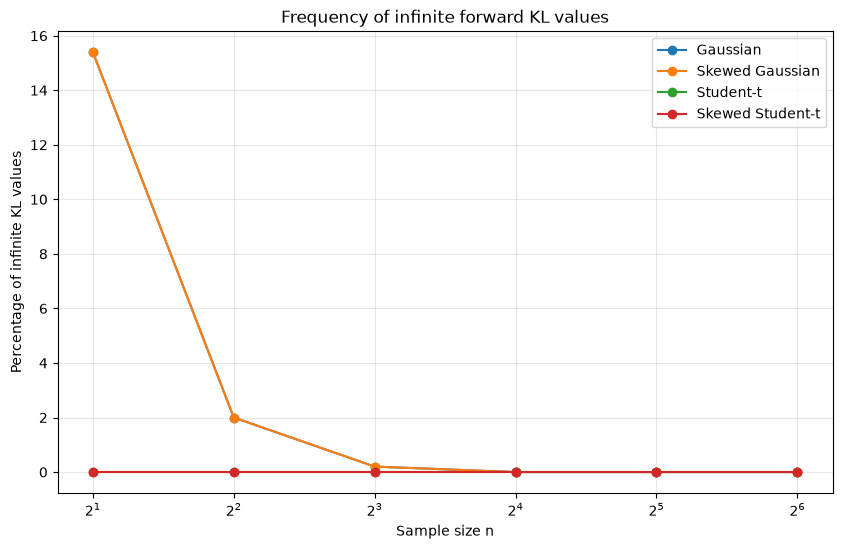

In [12]:
df_plot["is_infinite"] = ~np.isfinite(df_plot["kl"])

inf_summary = (
    df_plot
    .groupby(["n", "method"])["is_infinite"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))

for method in methods:
    sub = inf_summary[inf_summary["method"] == method]
    plt.plot(sub["n"], 100 * sub["is_infinite"], marker="o", label=method)

plt.xlabel("Sample size n")
plt.ylabel("Percentage of infinite KL values")
plt.title("Frequency of infinite forward KL values")
plt.legend()
plt.grid(alpha=0.3)
plt.xscale("log", base=2)
plt.show()

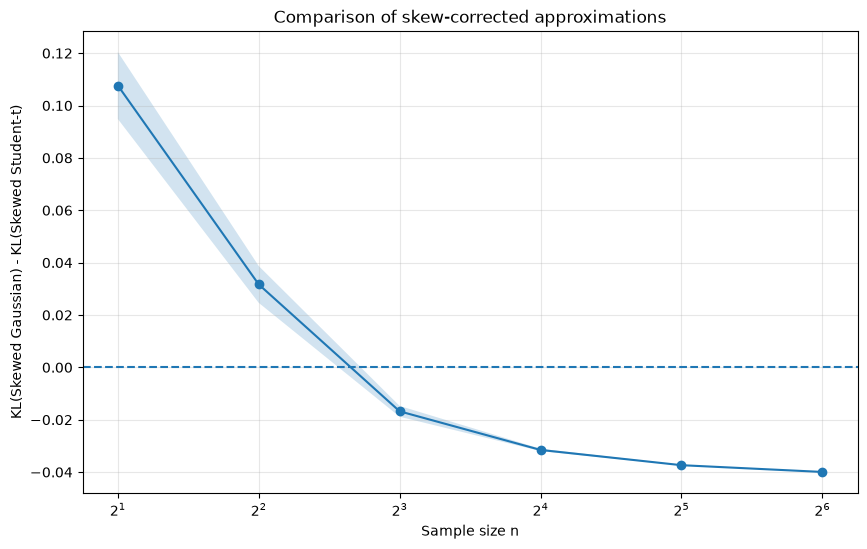

In [13]:
skew_only = df_plot[df_plot["skewed"]].copy()

wide_skew = (
    skew_only
    .pivot_table(
        index=["n", "replicate"],
        columns="family",
        values="kl"
    )
    .reset_index()
)

wide_skew["difference"] = wide_skew["gaussian"] - wide_skew["student_t"]

summary_diff = (
    wide_skew[np.isfinite(wide_skew["difference"])]
    .groupby("n")["difference"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

summary_diff["se"] = summary_diff["std"] / np.sqrt(summary_diff["count"])
summary_diff["lower"] = summary_diff["mean"] - 1.96 * summary_diff["se"]
summary_diff["upper"] = summary_diff["mean"] + 1.96 * summary_diff["se"]

plt.figure(figsize=(10, 6))
plt.plot(summary_diff["n"], summary_diff["mean"], marker="o")
plt.fill_between(summary_diff["n"], summary_diff["lower"], summary_diff["upper"], alpha=0.2)
plt.axhline(0, linestyle="--")

plt.xlabel("Sample size n")
plt.ylabel("KL(Skewed Gaussian) - KL(Skewed Student-t)")
plt.title("Comparison of skew-corrected approximations")
plt.grid(alpha=0.3)
plt.xscale("log", base=2)
plt.show()

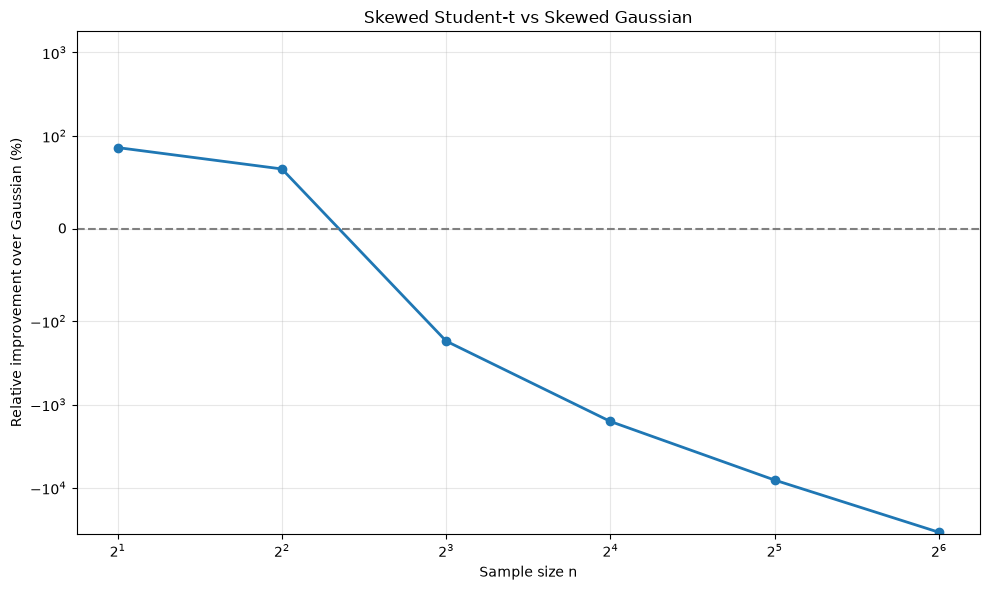

In [14]:
# Use the same paired simulations for both families
skew_only = df[df["skewed"]].copy()

wide = skew_only.pivot(
    index=["n", "replicate"],
    columns="family",
    values="kl"
).reset_index()

# Keep pairs where both divergences are finite
wide = wide[
    np.isfinite(wide["gaussian"])
    & np.isfinite(wide["student_t"])
]

# Mean KL for each family
summary = (
    wide.groupby("n")[["gaussian", "student_t"]]
    .mean()
    .reset_index()
)

# Percentage difference between mean KL values
summary["relative_improvement"] = 100 * (
    1 - summary["student_t"] / summary["gaussian"]
)

plt.figure(figsize=(10, 6))

plt.plot(
    summary["n"],
    summary["relative_improvement"],
    marker="o",
    linewidth=2
)

plt.axhline(0, color="gray", linestyle="--")
plt.yscale("symlog", linthresh=100)
plt.xscale("log", base=2)
plt.xlabel("Sample size n")
plt.ylabel("Relative improvement over Gaussian (%)")
plt.title("Skewed Student-t vs Skewed Gaussian")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()